# 04 · Haze correction by histogram matching

The baseline scores 98.8% on EuroSAT but only **56.5% on Kaggle**, because the training images
(Level-1C, with haze) look different from the test images (Level-2A, haze removed).
Here the training images are transformed so their band distributions match the test set.

**Methods compared**

| Method | Idea |
|---|---|
| `none` | no correction (the baseline) |
| `linear_p2p98` | per band y = a·x + b, mapping the 2nd/98th percentile to the test ones (last year's team M.A.R.S, reference) |
| `hist_all` | per-band histogram matching, fitted on all images |
| `hist_land` | per-band histogram matching, fitted on **land images only** |
| `hist_split` | two histogram matchings: one for land images, one for water images (each training image is assigned by its own brightness) |

**Why land only?** About 23.5% of test images are water vs 9% in training (`01_eda`). Matching *all*
pixels treats this class-mix difference as a brightness difference and distorts the land classes.
Normalising the test set with its own statistics failed for exactly this reason (tried in
`E01_baseline`: 47.8% vs 56.5%).

**How the methods are judged, without training or Kaggle submissions**

1. **Histogram distance** per band between corrected training images and test images, separately for land and water.
2. **Train-vs-test classifier**: a logistic regression tries to tell corrected training images from test images. 50% = it can't tell them apart = perfect correction.

All matchers are fitted on the **training split** and the unlabelled Kaggle images, and judged on the
**validation split**, which the fit never saw.

## 1 · Setup and data

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wasserstein_distance
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
from src.data import CLASSES, PROJECT_ROOT, TEST_BANDS, band_index, load_split, load_test, load_train
from src.plot_style import MUTED, TEST_COLOR, TRAIN_COLOR, apply_style
from src.preprocessing import HistogramMatcher, LinearPercentileMatcher, SplitMatcher, land_mask

apply_style()
rng = np.random.default_rng(0)

X_all, meta = load_train()
X_kaggle, _ = load_test()
split = load_split()

X_tr = np.asarray(X_all[np.flatnonzero(split["split"] == "train")])
X_va = np.asarray(X_all[np.flatnonzero(split["split"] == "val")])
y_va = split.loc[split["split"] == "val", "label"].values
X_kg = np.asarray(X_kaggle)

land_tr, land_va, land_kg = land_mask(X_tr), land_mask(X_va), land_mask(X_kg)
print(f"Water-like images: train split {(~land_tr).mean():.1%}, val {(~land_va).mean():.1%}, Kaggle {(~land_kg).mean():.1%}")
print("Classes of water-like val images:", pd.Series(y_va[~land_va]).value_counts().to_dict())

Water-like images: train split 9.0%, val 9.0%, Kaggle 23.5%
Classes of water-like val images: {'SeaLake': 363}


## 2 · Fit the corrections

`hist_land` uses only images whose mean near-infrared (B08) is at least 500, on both sides. Water
pixels are then mapped by the same curve; beyond the fitted range the curve continues in a straight
line (see `src/preprocessing.py`).

In [2]:
matchers = {
    "linear_p2p98": LinearPercentileMatcher.fit(X_tr, X_kg),
    "hist_all": HistogramMatcher.fit(X_tr, X_kg, name="hist_all"),
    "hist_land": HistogramMatcher.fit(X_tr[land_tr], X_kg[land_kg], name="hist_land"),
    "hist_split": SplitMatcher.fit(X_tr, X_kg),
}
corrected = {"none": X_va, **{name: m(X_va) for name, m in matchers.items()}}
METHODS = list(corrected)
METHOD_COLORS = {"none": TRAIN_COLOR, "linear_p2p98": "#1baf7a", "hist_all": "#eda100",
                 "hist_land": "#4a3aa7", "hist_split": "#e87ba4"}

### The mapping curves

How each method maps a training value (x) to a test-like value (y). The dashed line is "no change". `hist_split` uses the `hist_land` curve for land images and the dotted curve for water images.

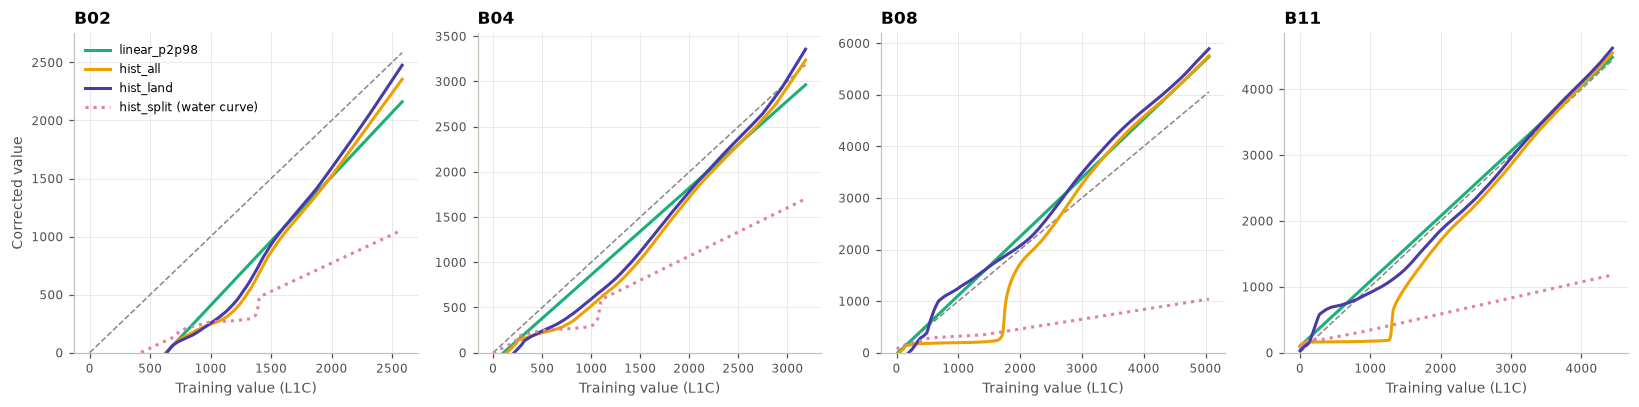

In [3]:
show_bands = ["B02", "B04", "B08", "B11"]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, band in zip(axes, show_bands):
    b = band_index(band)
    x = np.linspace(0, np.percentile(X_tr[:, b], 99.5), 300)
    ax.plot(x, x, color=MUTED, ls="--", lw=1)
    lin = matchers["linear_p2p98"]
    ax.plot(x, lin.a[b] * x + lin.b[b], color=METHOD_COLORS["linear_p2p98"], label="linear_p2p98")
    for name in ["hist_all", "hist_land"]:
        ax.plot(x, matchers[name].apply_band(x, b), color=METHOD_COLORS[name], label=name)
    ax.plot(x, matchers["hist_split"].water.apply_band(x, b), color=METHOD_COLORS["hist_split"], ls=":", label="hist_split (water curve)")
    ax.set_title(band, loc="left")
    ax.set_xlabel("Training value (L1C)")
    ax.set_ylim(bottom=0)
axes[0].set_ylabel("Corrected value")
axes[0].legend()
plt.tight_layout()
plt.show()

## 3 · Distributions after correction

Validation images after each correction (coloured) vs the Kaggle test images (orange), for
**land** images. Good corrections make the two lines overlap.

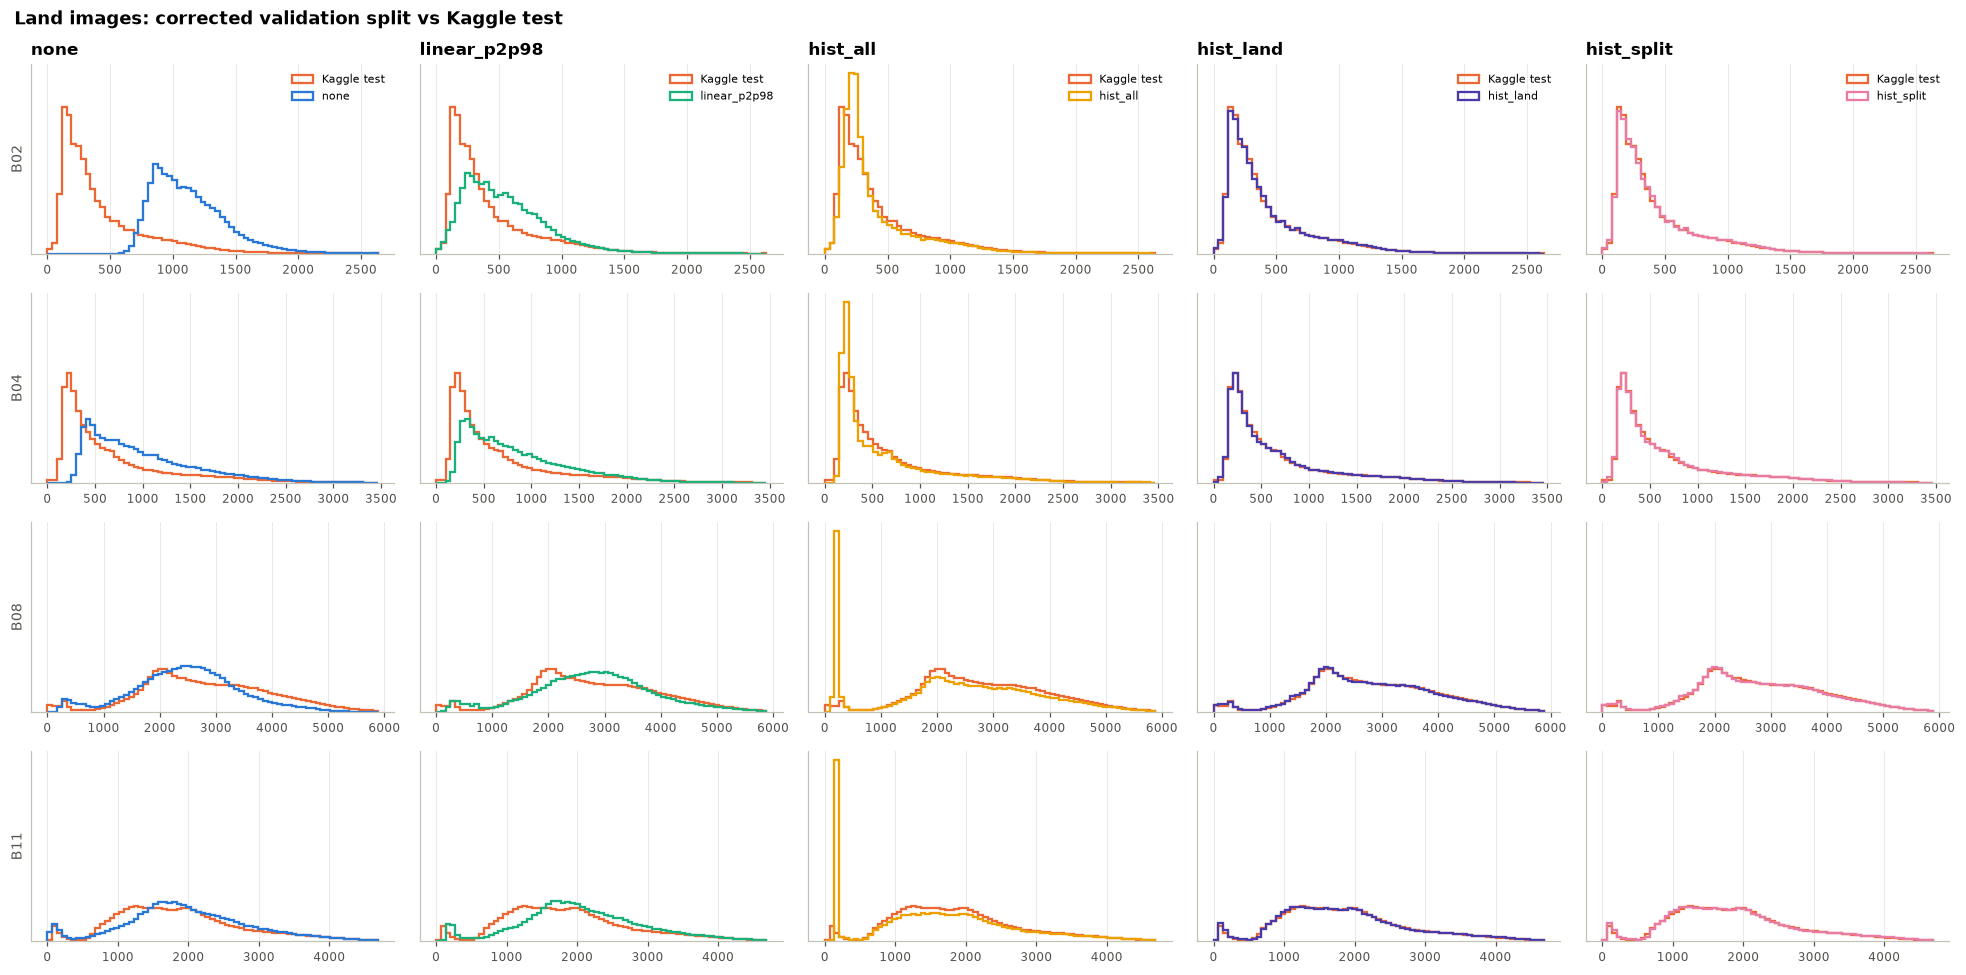

In [4]:
fig, axes = plt.subplots(len(show_bands), len(METHODS), figsize=(18, 9), sharey="row")
test_land = X_kg[land_kg]
for r, band in enumerate(show_bands):
    b = band_index(band)
    t = test_land[:, b, ::4, ::4].ravel()
    hi = np.percentile(t, 99.5)
    bins = np.linspace(0, hi, 70)
    for c, name in enumerate(METHODS):
        ax = axes[r, c]
        v = corrected[name][land_va][:, b, ::4, ::4].ravel()
        ax.hist(t, bins=bins, density=True, histtype="step", lw=1.5, color=TEST_COLOR, label="Kaggle test")
        ax.hist(v, bins=bins, density=True, histtype="step", lw=1.5, color=METHOD_COLORS[name], label=name)
        ax.set_yticks([])
        if r == 0:
            ax.set_title(name, loc="left")
        if c == 0:
            ax.set_ylabel(band)
        if r == 0:
            ax.legend(loc="upper right", fontsize=7)
fig.suptitle("Land images: corrected validation split vs Kaggle test", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

## 4 · Measure 1: histogram distance

Wasserstein distance per band ("how far must the histogram be moved to match the other one"),
divided by the test set's standard deviation so bands are comparable. 0 = identical. Computed
separately for land and water images, then averaged over the 12 bands.

In [5]:
def band_distances(a, b):
    """Per-band Wasserstein distance between two image sets, in units of b's std."""
    out = []
    for i in range(a.shape[1]):
        x, y = a[:, i, ::4, ::4].ravel(), b[:, i, ::4, ::4].ravel()
        out.append(wasserstein_distance(x, y) / y.std())
    return np.array(out)

dist = {}
for name in METHODS:
    dist[(name, "land")] = band_distances(corrected[name][land_va], X_kg[land_kg])
    dist[(name, "water")] = band_distances(corrected[name][~land_va], X_kg[~land_kg])

per_band = pd.DataFrame(dist, index=TEST_BANDS).round(2)
summary = pd.DataFrame({
    "land (mean over bands)": [per_band[(n, "land")].mean() for n in METHODS],
    "water (mean over bands)": [per_band[(n, "water")].mean() for n in METHODS],
}, index=METHODS).round(3)
summary

,land (mean over bands),water (mean over bands)
none,0.741,6.672
linear_p2p98,0.258,1.790
hist_all,0.272,0.817
hist_land,0.024,1.981
hist_split,0.024,0.158


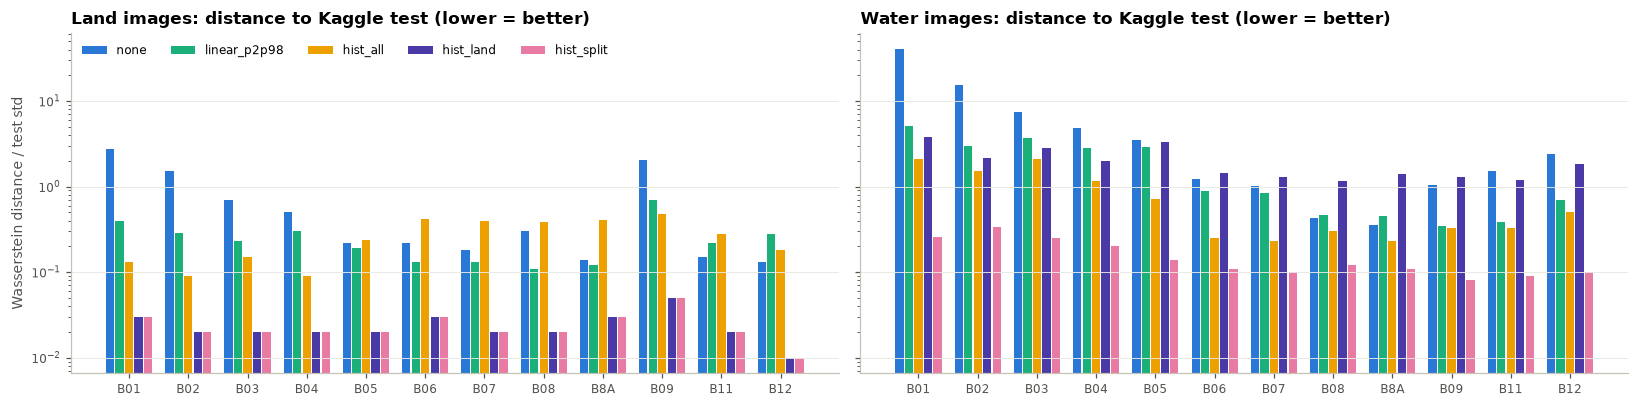

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8), sharey=True)
x = np.arange(12)
w = 0.16
for ax, part in zip(axes, ["land", "water"]):
    for i, name in enumerate(METHODS):
        ax.bar(x + (i - 2) * w, per_band[(name, part)], w - 0.02, color=METHOD_COLORS[name], label=name)
    ax.set_xticks(x, TEST_BANDS, fontsize=8)
    ax.set_title(f"{part.capitalize()} images: distance to Kaggle test (lower = better)", loc="left")
    ax.set_yscale("log")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Wasserstein distance / test std")
axes[0].legend(ncol=5, loc="upper left")
plt.tight_layout()
plt.show()

## 5 · Measure 2: can a classifier tell training from test images?

Each image is summarised by 62 numbers (per band: mean, std, 10th and 90th percentile; plus mean
NDVI and NDWI). A logistic regression learns to separate corrected validation images from Kaggle
test images (equal numbers of each, 5-fold cross-validation).

- **close to 100%**: the datasets are still easy to tell apart
- **close to 50%**: the correction made them indistinguishable

The "land only" column removes the class-mix difference (more water in the test set).

In [7]:
def image_features(x):
    x = x.astype(np.float32)
    f = [x.mean(axis=(2, 3)), x.std(axis=(2, 3)),
         np.percentile(x, 10, axis=(2, 3)), np.percentile(x, 90, axis=(2, 3))]
    nir, red, green = x[:, band_index("B08")], x[:, band_index("B04")], x[:, band_index("B03")]
    f.append(((nir - red) / (nir + red + 1e-6)).mean(axis=(1, 2))[:, None])
    f.append(((green - nir) / (green + nir + 1e-6)).mean(axis=(1, 2))[:, None])
    return np.hstack(f)

def domain_accuracy(a, b, seed=0):
    """Cross-validated accuracy of telling set a from set b (balanced)."""
    n = min(len(a), len(b))
    r = np.random.default_rng(seed)
    a, b = a[r.choice(len(a), n, replace=False)], b[r.choice(len(b), n, replace=False)]
    X = np.vstack([image_features(a), image_features(b)])
    y = np.r_[np.zeros(n), np.ones(n)]
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
    return cross_val_score(clf, X, y, cv=5, scoring="accuracy").mean()

domain = pd.DataFrame({
    "all images": [domain_accuracy(corrected[n], X_kg) for n in METHODS],
    "land only": [domain_accuracy(corrected[n][land_va], X_kg[land_kg]) for n in METHODS],
}, index=METHODS)
(domain * 100).round(1).rename(columns=lambda c: c + " (%)")

,all images (%),land only (%)
none,100.0,100.0
linear_p2p98,90.7,93.0
hist_all,83.8,89.8
hist_land,85.0,87.9
hist_split,83.0,87.9


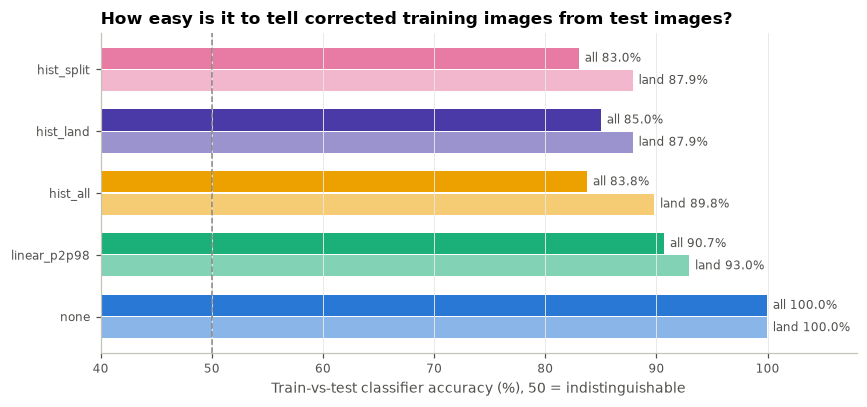

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(len(METHODS))
ax.barh(y + 0.18, domain["all images"] * 100, 0.34, color=[METHOD_COLORS[n] for n in METHODS])
ax.barh(y - 0.18, domain["land only"] * 100, 0.34, color=[METHOD_COLORS[n] for n in METHODS], alpha=0.55)
for i, n in enumerate(METHODS):
    ax.text(domain.loc[n, "all images"] * 100 + 0.5, i + 0.18, f"all {domain.loc[n, 'all images']:.1%}", va="center", fontsize=8, color="#52514e")
    ax.text(domain.loc[n, "land only"] * 100 + 0.5, i - 0.18, f"land {domain.loc[n, 'land only']:.1%}", va="center", fontsize=8, color="#52514e")
ax.axvline(50, color=MUTED, ls="--", lw=1)
ax.set_yticks(y, METHODS)
ax.set_xlim(40, 108)
ax.set_xlabel("Train-vs-test classifier accuracy (%), 50 = indistinguishable")
ax.set_title("How easy is it to tell corrected training images from test images?", loc="left")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 6 · What the corrected images look like

The same validation images (one per class) under each method, all with the same display scaling,
next to random Kaggle test images. The display scale is set for test-like values (0–1500).

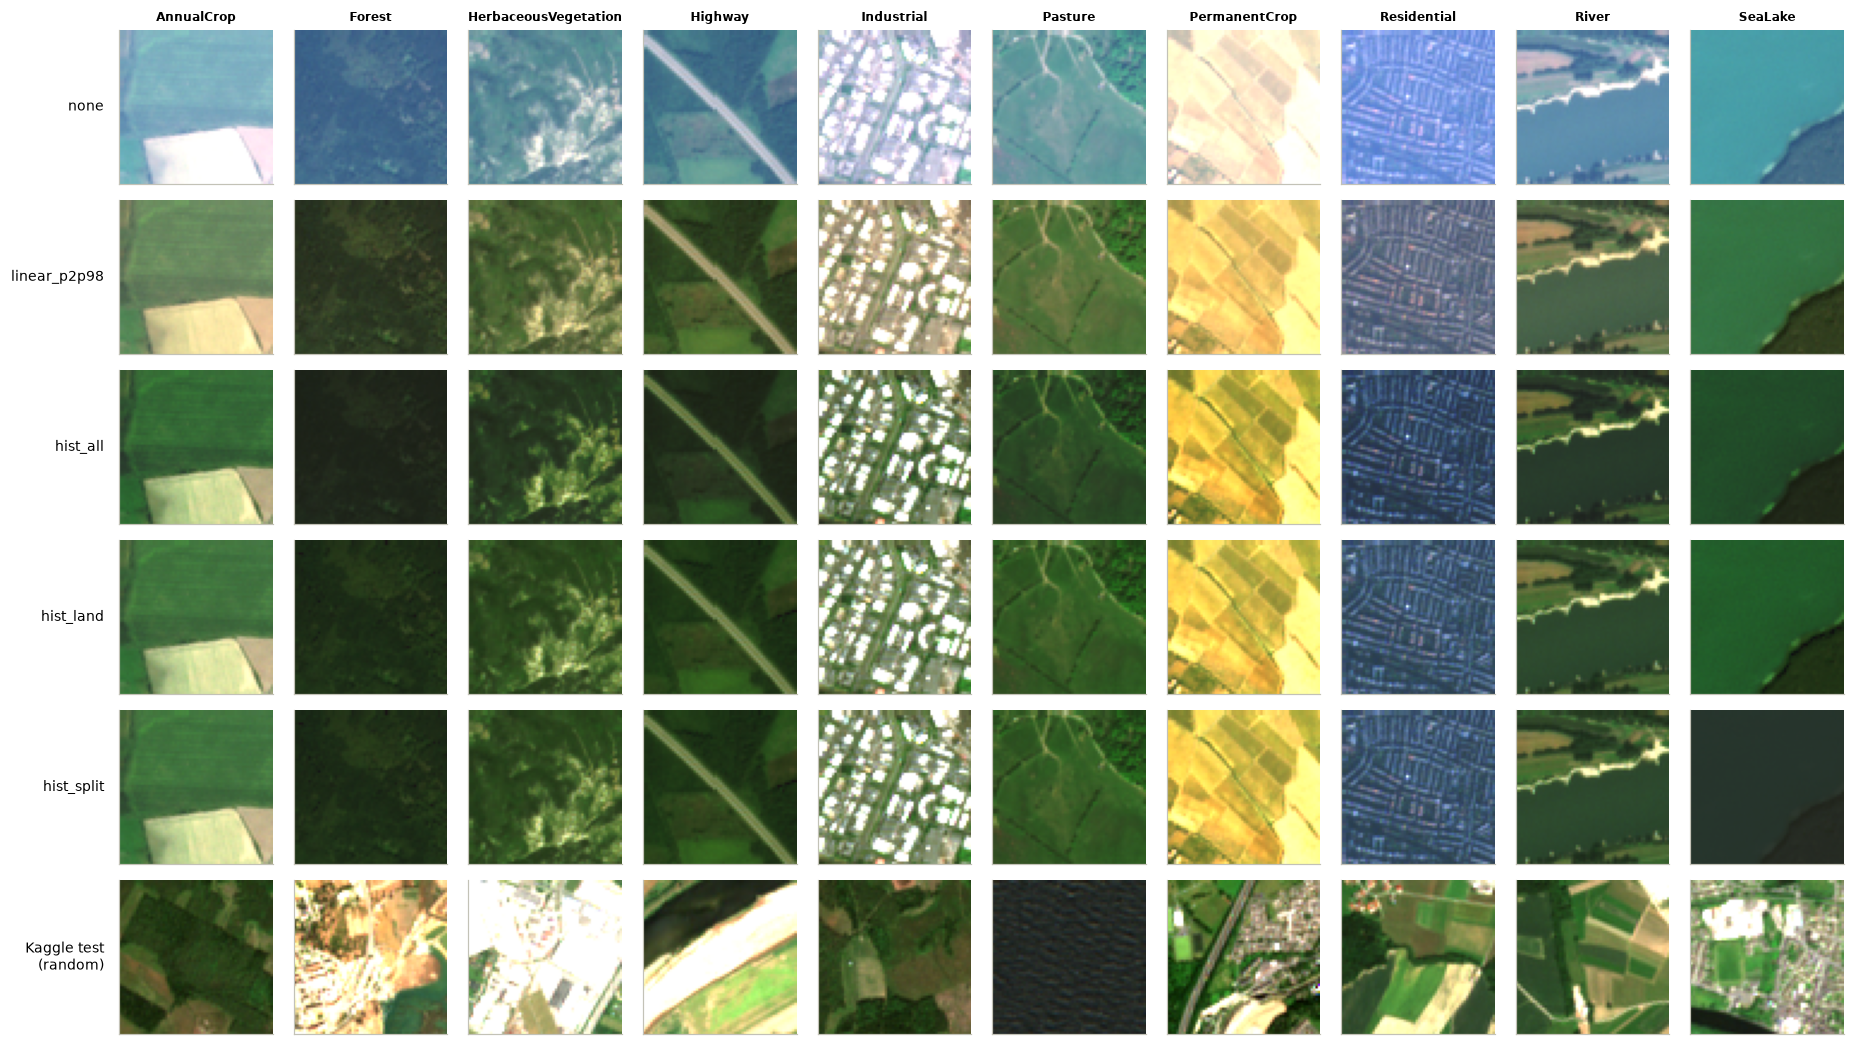

In [9]:
def to_rgb(img, vmax=1500):
    rgb = img[[band_index("B04"), band_index("B03"), band_index("B02")]].astype(np.float32)
    return np.clip(rgb / vmax, 0, 1).transpose(1, 2, 0)

va_labels = np.asarray(y_va)
examples = [rng.choice(np.flatnonzero(va_labels == c)) for c in CLASSES]
kg_examples = rng.choice(len(X_kg), len(CLASSES), replace=False)

fig, axes = plt.subplots(len(METHODS) + 1, len(CLASSES), figsize=(17, 9.6))
for r, name in enumerate(METHODS):
    for c, i in enumerate(examples):
        axes[r, c].imshow(to_rgb(corrected[name][i]))
        if r == 0:
            axes[r, c].set_title(CLASSES[c], fontsize=8)
    axes[r, 0].text(-0.1, 0.5, name, transform=axes[r, 0].transAxes, ha="right", va="center", fontsize=9)
for c, i in enumerate(kg_examples):
    axes[-1, c].imshow(to_rgb(X_kg[i]))
axes[-1, 0].text(-0.1, 0.5, "Kaggle test\n(random)", transform=axes[-1, 0].transAxes, ha="right", va="center", fontsize=9)
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.tight_layout()
plt.show()

## 7 · Save the corrections

In [10]:
out_dir = PROJECT_ROOT / "artifacts" / "preprocessing"
out_dir.mkdir(parents=True, exist_ok=True)
for name, m in matchers.items():
    m.save(out_dir / f"{name}.json")

results = pd.concat([summary, (domain * 100).round(1).add_prefix("domain acc % ")], axis=1)
results.to_csv(out_dir / "comparison.csv")
print("Saved to", out_dir.relative_to(PROJECT_ROOT))
results

Saved to artifacts/preprocessing


,land (mean over bands),water (mean over bands),domain acc % all images,domain acc % land only
none,0.741,6.672,100.0,100.0
linear_p2p98,0.258,1.790,90.7,93.0
hist_all,0.272,0.817,83.8,89.8
hist_land,0.024,1.981,85.0,87.9
hist_split,0.024,0.158,83.0,87.9


## 8 · What still differs after correction?

The classifier still separates the datasets about 85% of the time. Which image properties give
them away after `hist_split`? Each feature group is tested on its own (land images).

In [11]:
best = matchers["hist_split"](X_va)[land_va].astype(np.float32)
test_land_f = X_kg[land_kg].astype(np.float32)

def separability(fa, fb, seed=0):
    n = min(len(fa), len(fb))
    r = np.random.default_rng(seed)
    fa, fb = fa[r.choice(len(fa), n, replace=False)], fb[r.choice(len(fb), n, replace=False)]
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
    return cross_val_score(clf, np.vstack([fa, fb]), np.r_[np.zeros(n), np.ones(n)], cv=5).mean()

feature_groups = {
    "brightness (mean per band)": lambda x: x.mean(axis=(2, 3)),
    "colour (band ratios)": lambda x: x.mean(axis=(2, 3)) / x.mean(axis=(1, 2, 3))[:, None],
    "contrast (std within image)": lambda x: x.std(axis=(2, 3)),
    "fine texture (neighbour differences)": lambda x: np.abs(np.diff(x, axis=3)).mean(axis=(2, 3)) / (x.std(axis=(2, 3)) + 1),
}
remaining = pd.Series({k: separability(f(best), f(test_land_f)) for k, f in feature_groups.items()})
contrast_ratio = pd.Series(np.median(test_land_f.std(axis=(2, 3)), 0) / np.median(best.std(axis=(2, 3)), 0), index=TEST_BANDS)

print("Classifier accuracy per feature group (50% = no difference):")
print((remaining * 100).round(1).astype(str) + " %")
print()
print("Contrast within images, test / corrected train (median):")
print(contrast_ratio.round(2).to_dict())

Classifier accuracy per feature group (50% = no difference):
brightness (mean per band)              54.1 %
colour (band ratios)                    51.9 %
contrast (std within image)             84.4 %
fine texture (neighbour differences)    75.3 %
dtype: str

Contrast within images, test / corrected train (median):
{'B01': 1.9299999475479126, 'B02': 1.3600000143051147, 'B03': 1.2599999904632568, 'B04': 1.2799999713897705, 'B05': 1.2999999523162842, 'B06': 1.1699999570846558, 'B07': 1.1200000047683716, 'B08': 1.100000023841858, 'B8A': 1.149999976158142, 'B09': 1.8600000143051147, 'B11': 1.25, 'B12': 1.2799999713897705}


## 9 · Conclusion

| Method | Land distance | Water distance | Train-vs-test classifier | Verdict |
|---|---|---|---|---|
| `none` | 0.74 | 6.67 | 100% | baseline |
| `linear_p2p98` (last year) | 0.26 | 1.79 | 91% | clear improvement, but a straight line can't follow the curved shift |
| `hist_all` | 0.27 | 0.82 | 84% | **distorts land**: squashes NIR/SWIR values of vegetation to water level, because the test set has more water |
| `hist_land` | **0.02** | 1.98 | 85% | land almost perfect, water poor |
| **`hist_split`** | **0.02** | **0.16** | 83% | **best on both** → used for the next training run |

**What the correction fixes:** after `hist_split`, brightness and colour of corrected training images
can no longer be told apart from the test images (classifier ≈ 50–54% on those features).

**What it can't fix:** test images have more **contrast within each image** (about 10–35% more in most
bands, almost double in B01/B09). Haze lowers contrast by a different amount in every image, and one
curve for the whole dataset can't undo that. Next experiments for this:

1. **Per-image contrast augmentation** during training (random contrast stretch per image and band), so the model learns to ignore contrast. → done in `E04_contrast_aug`.
2. **Per-image normalisation** (each image standardised by its own mean/std), which removes brightness and contrast differences completely, at the cost of absolute brightness information. (Not tried yet.)
3. **Dropping B01 and B09**, the atmospheric bands that differ the most. (Not tried yet.)

**Next step:** train the baseline model again with `hist_split` applied to all EuroSAT images,
changing nothing else, and compare its Kaggle score with 56.5% (`E02_hist_split`: **64.06%**, +7.6 points).